## Procurement Analytics
This is a case study proposed for analyzing a sample data from procurement process. The company wants to analyze if it is good option to use 'Contract' or 'Spot' buying mode.




### 1. Importing the Libraries Required

In [184]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.rcParams['figure.figsize'] = [4, 3]

import warnings as wr

wr.filterwarnings("ignore")

from IPython.display import Image, display

### 2. Getting the datasets

There are 4 datasets:
1. `purchase_metadata_SAMPLE.xlsx`: One row per purchase order line
2. `material_classification_SAMPLE.csv`: Per material data (category, shelf life in days and storage cost)
3. `material_price_benchmark_SAMPLE.csv`: Historical and planned reference prices per material and center
4. `center_storage_capacity_SAMPLE.csv`: Total storage capacity per center

In [2]:
# Loading the files
file_path = Path("C:/Users/asala/Downloads/prueba-tecnica-iluma")
p_m = pd.read_excel(file_path / "purchase_metadata_SAMPLE.xlsx")
m_c = pd.read_csv(file_path / "material_classification_SAMPLE.csv", sep=';')
m_p = pd.read_csv(file_path / "material_price_benchmark_SAMPLE.csv", sep=';')
c_s = pd.read_csv(file_path / "center_storage_capacity_SAMPLE.csv", sep=';')

### 3. Explore the structure of all files

For this matter we will use `df.shape` to see the structure of the file (number of rows, number of columns); and `df.head()` to see first five rows and all the columns in each file.

1. **File:** `purchase_metadata_SAMPLE.xlsx`

In [3]:
# Structure of purchase_metadata_SAMPLE.xlsx
p_m.shape

(165, 12)

The previous result means `purchase_metadata_SAMPLE.xlsx` has 165 rows and 12 columns.

In [4]:
# Sample of purchase_metadata_SAMPLE.xlsx (first five rows and 12 columns)
p_m.head()

,POSampleID,SupplierCode,MaterialCode,Center,OrderDate,BuyingMode,OrderQuantity,UnitPriceUSD,TransportCostUSD,DaysInStorage,BatchNumber,NegotiatorID
0,PO10001-P,V-100070,MAT-1006,P,2024-01-24,Contract,829,26.67,443.79,45.0,B6966,A.Villalba
1,PO10002-P,V-100077,MAT-1007,P,2024-05-05,Spot,1400,24.99,1400.94,116.0,B8776,A.Villalba
2,PO10003-P,V-100049,MAT-1001,P,2024-05-07,Contract,1097,31.99,1275.31,15.0,B3357,L.Fonseca
3,PO10004-P,V-100014,MAT-1008,P,2024-07-20,Spot,382,4.64,138.79,114.0,B3543,L.Fonseca
4,PO10005-S,V-100112,MAT-1005,S,2024-03-17,Spot,1572,6.54,754.74,150.0,B8032,M.Cardenas


2. **File:** `material_classification_SAMPLE.csv`

In [5]:
# Structure of material_classification_SAMPLE.csv
m_c.shape

(25, 9)

The previous result means `material_classification_SAMPLE.csv` has 25 rows and 9 columns.

In [6]:
# Sample of material_classification_SAMPLE.csv (first five rows and 9 columns)
m_c.head()

,MaterialCode,MaterialName,Category,MaterialGroupName,MaterialGroupName2,MaterialType,IsUnknownGroup,ShelfLifeDays,StorageCostPerUnitPerDay
0,MAT-1001,Yellow Corn,Raw Materials,Grains & Oilseeds,GRAINS_&_OILSEEDS,Raw Material,False,76.0,0.0629
1,MAT-1002,Soybean Meal,Raw Materials,Grains & Oilseeds,GRAINS_&_OILSEEDS,Raw Material,False,85.0,0.0510
2,MAT-1003,Wheat Bran,Raw Materials,Grains & Oilseeds,GRAINS_&_OILSEEDS,Raw Material,False,44.0,0.0579
3,MAT-1004,Vitamin Premix,Raw Materials,Additives & Premixes,ADDITIVES_&_PREMIXES,Raw Material,False,47.0,0.0396
4,MAT-1005,Amino Acid Blend,Raw Materials,Additives & Premixes,ADDITIVES_&_PREMIXES,Raw Material,False,42.0,0.0614


3. **File:** `material_price_benchmark_SAMPLE.csv`

In [7]:
# Structure of material_price_benchmark_SAMPLE.csv
m_p.shape

(60, 8)

The previous result means `material_price_benchmark_SAMPLE.csv` has 60 rows and 8 columns.

In [8]:
# Sample of material_price_benchmark_SAMPLE.csv (first five rows and 8 columns)
m_p.head()

,MaterialCode,Center,PreviousPriceUSD,PreviousPriceDate,PlannedPrice2USD,PlannedPriceDate2,PlannedPrice3USD,PlannedPriceDate3
0,MAT-1001,S,31.68,10/02/2024,33.21,17/03/2024,34.28,27/04/2024
1,MAT-1001,P,32.77,1/02/2024,32.92,23/03/2024,34.05,9/05/2024
2,MAT-1002,N,19.76,20/02/2024,19.35,26/03/2024,19.41,17/05/2024
3,MAT-1002,S,18.81,22/01/2024,20.27,15/03/2024,19.93,28/04/2024
4,MAT-1002,P,20.05,18/02/2024,20.38,29/03/2024,21.93,2/05/2024


4. **File:** `center_storage_capacity_SAMPLE.csv`

In [9]:
# Structure of center_storage_capacity_SAMPLE.csv
c_s.shape

(3, 3)

The previous result means `center_storage_capacity_SAMPLE.csv` has 3 rows and 3 columns.

In [10]:
# Sample of center_storage_capacity_SAMPLE.csv (all rows and 3 columns)
c_s.head()

,Center,CenterName,StorageCapacityUnits
0,N,North Plant,60000
1,S,South Plant,42000
2,P,Port Bonded Warehouse,18000


### 4. Analyzing the file `purchase_metadata_SAMPLE.xlsx`

Let's see the characteristics of the columns of the data. With `df.info()` we could see if there is empty values and the data type for each column. This is so important in order to clean, transform and complete the data.

In [11]:
p_m.info()

<class 'pandas.DataFrame'>
RangeIndex: 165 entries, 0 to 164
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   POSampleID        165 non-null    str    
 1   SupplierCode      165 non-null    str    
 2   MaterialCode      165 non-null    str    
 3   Center            165 non-null    str    
 4   OrderDate         165 non-null    str    
 5   BuyingMode        165 non-null    str    
 6   OrderQuantity     165 non-null    int64  
 7   UnitPriceUSD      165 non-null    float64
 8   TransportCostUSD  161 non-null    float64
 9   DaysInStorage     160 non-null    float64
 10  BatchNumber       165 non-null    str    
 11  NegotiatorID      153 non-null    str    
dtypes: float64(3), int64(1), str(8)
memory usage: 15.6 KB


#### 4.1. Structure of the `MaterialCode` column

In [12]:
# Analyzing the structure of the 'MaterialCode' column
p_m['MaterialCode'].value_counts()

MaterialCode
MAT-01015    12
MAT-1014     10
MAT-1001      9
MAT-1008      9
MAT-1005      9
MAT-1023      9
MAT-1021      9
MAT-1007      8
MAT-1010      8
MAT-1006      7
MAT-1018      7
MAT-1019      6
MAT-1016      6
MAT-1011      6
MAT-1017      6
MAT-1003      6
MAT-1002      6
MAT-1024      6
MAT-1012      5
MAT-01004     4
MAT-1009      4
MAT-1022      4
MAT-1013      3
MAT-1020      3
MAT-1025      3
Name: count, dtype: int64

Since `MaterialCode` has some inconsistencies, first it is necessary to normalize the codes for `MAT-01004` to `MAT-1004` and `MAT-01015` to `MAT-1015`, in order to have the same structure for all, and to have consistency with the list of `MaterialCode` in `material_class.csv` file.

In [13]:
p_m['MaterialCode'] = p_m['MaterialCode'].str.replace(r'^MAT-0+', 'MAT-', regex=True)

In [14]:
# 'MaterialCode' values in 'purchase_metadate.xlsx'
sorted(p_m['MaterialCode'].unique())

['MAT-1001',
 'MAT-1002',
 'MAT-1003',
 'MAT-1004',
 'MAT-1005',
 'MAT-1006',
 'MAT-1007',
 'MAT-1008',
 'MAT-1009',
 'MAT-1010',
 'MAT-1011',
 'MAT-1012',
 'MAT-1013',
 'MAT-1014',
 'MAT-1015',
 'MAT-1016',
 'MAT-1017',
 'MAT-1018',
 'MAT-1019',
 'MAT-1020',
 'MAT-1021',
 'MAT-1022',
 'MAT-1023',
 'MAT-1024',
 'MAT-1025']

In [15]:
# 'MaterialCode' values in 'material_classification_SAMPLE.csv'
sorted(m_c['MaterialCode'].unique())

['MAT-1001',
 'MAT-1002',
 'MAT-1003',
 'MAT-1004',
 'MAT-1005',
 'MAT-1006',
 'MAT-1007',
 'MAT-1008',
 'MAT-1009',
 'MAT-1010',
 'MAT-1011',
 'MAT-1012',
 'MAT-1013',
 'MAT-1014',
 'MAT-1015',
 'MAT-1016',
 'MAT-1017',
 'MAT-1018',
 'MAT-1019',
 'MAT-1020',
 'MAT-1021',
 'MAT-1022',
 'MAT-1023',
 'MAT-1024',
 'MAT-1025']

Now, all values of `MaterialCode` column in `purchase_metadata_SAMPLE.xlsx` file are normalized, and coincide with the values in `MaterialCode` column in `material_classification_SAMPLE.csv` file.

#### 4.2. Transform datatype of `OrderDate` column

It is recommended to transform the datatype of this column from `str` to `datetime`. This is helpful then, because it is required to filter registers with `OrderDate` from January 2024 to September 2024.

In [16]:
# Converting the datatype from str to datetime
p_m['OrderDate'] = pd.to_datetime(p_m['OrderDate'], format='%Y-%m-%d')

In [17]:
# Checking the datatype of column 'OrderDate'
p_m.info()

<class 'pandas.DataFrame'>
RangeIndex: 165 entries, 0 to 164
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   POSampleID        165 non-null    str           
 1   SupplierCode      165 non-null    str           
 2   MaterialCode      165 non-null    str           
 3   Center            165 non-null    str           
 4   OrderDate         165 non-null    datetime64[us]
 5   BuyingMode        165 non-null    str           
 6   OrderQuantity     165 non-null    int64         
 7   UnitPriceUSD      165 non-null    float64       
 8   TransportCostUSD  161 non-null    float64       
 9   DaysInStorage     160 non-null    float64       
 10  BatchNumber       165 non-null    str           
 11  NegotiatorID      153 non-null    str           
dtypes: datetime64[us](1), float64(3), int64(1), str(7)
memory usage: 15.6 KB


Now, let's filter the registers in the required period of time.

In [18]:
# Filtering the data by 'OrderDate', between January and September 2024
p_m = p_m[p_m['OrderDate'].between('2024-01-01', '2024-09-30')]

#### 4.3. Check consistency between `POSampleID` suffix with `Center` values

I will assume the suffix of `POSampleID` as the correct data for `Center` values. So let's transform the column based on this assumption.

In [19]:
# Assign the suffix of 'POSampleID' as value for 'Center'
p_m['Center'] = p_m['POSampleID'].str.split('-').str[1]

In [20]:
# Check coincidence bewteen suffix & 'Center' value (last letter of POSampleID==Center Value)
(p_m['POSampleID'].str.split('-').str[1] == p_m['Center']).value_counts()

True    164
Name: count, dtype: int64

Based on the previous result, suffix and `Center` column value coincide.

#### 4.4. Missing Values on `TransportCostUSD`, `DaysInStorage` & `NegotiatorID`

There are three columns with missing values: `TransportCostUSD`, `DaysInStorage` & `NegotiatorID`.

In [21]:
p_m.loc[p_m['TransportCostUSD'].isna() | p_m['DaysInStorage'].isna() | p_m['NegotiatorID'].isna(), ['TransportCostUSD', 'DaysInStorage', 'NegotiatorID']]

,TransportCostUSD,DaysInStorage,NegotiatorID
14,NaN,37.0,NaN
18,4236.40,72.0,NaN
21,1260.94,134.0,NaN
30,43.16,NaN,M.Cardenas
41,1212.19,129.0,NaN
54,NaN,175.0,L.Fonseca
62,1183.97,24.0,NaN
65,504.78,NaN,NaN
72,770.04,10.0,NaN
73,713.60,NaN,M.Cardenas


For `NegotiatorID` it will assumed that the information is not critical for the analysis required in this case study. So the rows with this missing values in `NegotiatorID` will stand in the data.

For `TransportCostUSD` and `DaysInStorage` the rows with missing values will be dropped. It is because the total number of rows for this case is **9**, which represents only **5,5 %** of total rows. Furthemore, of this total **5 rows** corrsponds to *Contract* `BuyingMode` and **4 rows** correspond to *Spot* `BuyingMode`. This is a balanced droping, so it will not affect considerably the analysis required.

In [22]:
p_m.loc[p_m['TransportCostUSD'].isna() | p_m['DaysInStorage'].isna(), ['TransportCostUSD', 'DaysInStorage', 'BuyingMode']]

,TransportCostUSD,DaysInStorage,BuyingMode
14,NaN,37.0,Contract
30,43.16,NaN,Contract
54,NaN,175.0,Spot
65,504.78,NaN,Contract
73,713.60,NaN,Spot
122,192.27,NaN,Spot
131,NaN,3.0,Contract
143,541.44,NaN,Contract
161,NaN,83.0,Spot


Based on the previous assumptions, the `purchase_metadata_SAMPLE.xlsx` dataset now has 155 rows.

In [24]:
p_m.dropna(subset=['TransportCostUSD', 'DaysInStorage'], inplace=True)
p_m.shape

(155, 12)

After this, the `purchase_metadata_SAMPLE.xlsx` dataset is normalized, filtered and cleaned. It is ready to use for the required analysis.

### 5. Calculation of the per unit cost of every Purchase Order

For this calculation lets define the following variables (those highlitghed in gray are given in the data set):

- `PerUnitTransportCost`: It is the transportation cost per unit.
    - `PerUnitTransportCost` = `TransportCostUSD` / `OrderQuantity`
- `PerUnitStorageCost`: It is the storage cost per unit.
    - `PerUnitStorageCost` = `DaysInStorage` * `StorageCostPerUnitPerDay` 
- `POUnitCost`: It is the total cost per unit for each purchase order.
    - `POUnitCost` = `UnitPriceUSD` + `PerUnitTransportCost` + `PerUnitStorageCost`

In [ ]:
p_m_w = p_m.join(m_c.set_index('MaterialCode'), on='MaterialCode', how='left')

,POSampleID,SupplierCode,MaterialCode,Center,OrderDate,BuyingMode,OrderQuantity,UnitPriceUSD,TransportCostUSD,DaysInStorage,BatchNumber,NegotiatorID,MaterialName,Category,MaterialGroupName,MaterialGroupName2,MaterialType,IsUnknownGroup,ShelfLifeDays,StorageCostPerUnitPerDay
0,PO10001-P,V-100070,MAT-1006,P,2024-01-24,Contract,829,26.67,443.79,45.0,B6966,A.Villalba,Enzyme Complex,Raw Materials,Additives & Premixes,ADDITIVES_&_PREMIXES,Raw Material,False,62.0,0.0265
1,PO10002-P,V-100077,MAT-1007,P,2024-05-05,Spot,1400,24.99,1400.94,116.0,B8776,A.Villalba,Crude Palm Oil,Raw Materials,Fats & Oils,FATS_&_OILS,Raw Material,False,90.0,0.0417
2,PO10003-P,V-100049,MAT-1001,P,2024-05-07,Contract,1097,31.99,1275.31,15.0,B3357,L.Fonseca,Yellow Corn,Raw Materials,Grains & Oilseeds,GRAINS_&_OILSEEDS,Raw Material,False,76.0,0.0629
3,PO10004-P,V-100014,MAT-1008,P,2024-07-20,Spot,382,4.64,138.79,114.0,B3543,L.Fonseca,Soy Oil,Raw Materials,Fats & Oils,FATS_&_OILS,Raw Material,False,65.0,0.0286
4,PO10005-S,V-100112,MAT-1005,S,2024-03-17,Spot,1572,6.54,754.74,150.0,B8032,M.Cardenas,Amino Acid Blend,Raw Materials,Additives & Premixes,ADDITIVES_&_PREMIXES,Raw Material,False,42.0,0.0614
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
159,PO10160-N,V-100035,MAT-1007,N,2024-06-11,Contract,1316,30.94,1057.66,15.0,B8229,J.Restrepo,Crude Palm Oil,Raw Materials,Fats & Oils,FATS_&_OILS,Raw Material,False,90.0,0.0417
160,PO10161-S,V-100077,MAT-1016,S,2024-07-09,Spot,1252,7.47,539.22,137.0,B1206,NaN,Gearbox Seal Kit,MRO / Spare Parts,Mechanical Spares,MECHANICAL_SPARES,Non-Raw Material,False,1472.0,0.0063
162,PO10163-N,V-100091,MAT-1015,N,2024-01-12,Contract,1061,22.24,624.16,32.0,B4831,L.Fonseca,Bearing Assembly,MRO / Spare Parts,Mechanical Spares,MECHANICAL_SPARES,Non-Raw Material,False,1295.0,0.0085
163,PO10164-N,V-100084,MAT-1006,N,2024-03-14,Spot,2214,23.78,3271.34,57.0,B3447,A.Villalba,Enzyme Complex,Raw Materials,Additives & Premixes,ADDITIVES_&_PREMIXES,Raw Material,False,62.0,0.0265


#### 5.2. `PerUnitTransportCost`

Given the column `TransportCostUSD` it will be calculated a new column `PerUnitTransportCost` based on the `OrderQuantity` of each purchase order.

In [ ]:
# New column 'PerUnitTransportCost' based on 'TransportCostUSD' & 'OrderQuantity'
p_m_w['PerUnitTransportCost'] = p_m_w['TransportCostUSD'] / p_m_w['OrderQuantity']

#### 5.3. `PerUnitStorageCost`

Given the columns `DaysInStorage` and `StorageCostPerUnitPerDay` it will be calculated a new column `PerUnitStorageCost` in order to define how much it cost the storage of each unit of the respective purchase order before it was consumed.

In [27]:
# New column 'PerUnitStorageCost' based on 'DaysInStorage' & 'StorageCostPerUnitPerDay'
p_m_w['PerUnitStorageCost'] = p_m_w['DaysInStorage'] * p_m_w['StorageCostPerUnitPerDay']

#### 5.4. `POUnitCost`

Now it will be calculated the `POUnitCost`, which is the per unit cost of each purchase order. This is relevant because it allows to compare the cost for each material based on the two different buying modes (contract vs. spot). This cost is the sum of `UnitPriceUSD` , `PerUnitTransportCost` and `PerUnitStorageCost`.

In [28]:
# New column 'POUnitCost'
p_m_w['POUnitCost'] = p_m_w['UnitPriceUSD'] + p_m_w['PerUnitTransportCost'] + p_m_w['PerUnitStorageCost']

#### 5.5. `DaysLeft` for Identifying Expired Products

It will be created a column for calculating the `DaysLeft` until expiration of the product. Those products in which the `DaysInStorage` have surpased the `ShelfLifeDays` the result will be negative, so it could be assumed the product is expired.

In [ ]:
# 'DaysLeft' will allow to identify if the product is expired, when the result is negative
p_m_w['DaysLeft'] = p_m_w['ShelfLifeDays'] - p_m_w['DaysInStorage']

### 6. Business & Procurement Interpretation

The question proposed for this analysis is:
- What can this data tell us about whether opportunistic buying is cost-effective, and under what conditions?

For answering this question the dataset will be filtered and sorted based on the following conditions:
- Remove those rows whitout `POUnitCost`.
- Show only columns `MaterialCode`, `BuyingMode`, `DaysLeft`, `UnitPriceUSD`, `POUnitCost`, `POsampleID`.
- Order the filtered dataset based on 1.`MaterialCode`, 2.`BuyingMode`, 3.`POUnitCost`.

In [92]:
(
    p_m_w[(p_m_w['POUnitCost'].notnull())]
    [['POSampleID', 'MaterialCode', 'BuyingMode', 'DaysLeft', 'UnitPriceUSD', 'POUnitCost']]
    .sort_values(by=['MaterialCode', 'BuyingMode', 'POUnitCost'])
)

,POSampleID,MaterialCode,BuyingMode,DaysLeft,UnitPriceUSD,POUnitCost
32,PO10033-S,MAT-1001,Contract,56.0,31.72,33.803685
2,PO10003-P,MAT-1001,Contract,61.0,31.99,34.096043
27,PO10028-S,MAT-1001,Contract,53.0,32.11,34.471964
7,PO10008-P,MAT-1001,Contract,54.0,33.20,35.294346
96,PO10097-S,MAT-1001,Contract,39.0,33.13,36.632100
...,...,...,...,...,...,...
102,PO10103-N,MAT-1018,Contract,2349.0,33.01,34.050619
48,PO10049-S,MAT-1018,Contract,2317.0,32.44,34.062792
126,PO10127-P,MAT-1018,Contract,2347.0,33.33,34.629276
147,PO10148-P,MAT-1018,Contract,2350.0,33.61,35.019924


#### 6.1. Cases when Opportunistic Buying is **NOT** Cost-Effective

1. Purchase Orders for **MAT-1005**:
    - In the **Spot** BuyingMode the **minimum** value for POUnitCost is **13.47**, while the **maximum** value for **Contract** BuyingMode is **10.38**. It is a difference of **3.09** in the POUnitCost.
    - Event though the UnitPriceUSD for Spot BuyingMode is smaller than Contract BuyingMode, the fact that the product is expired generates the final POUnitCost be greater in the Spot case.
    - This is a material from Raw Materials category.
    - In this case the opportunistic buying is not cost-effective.

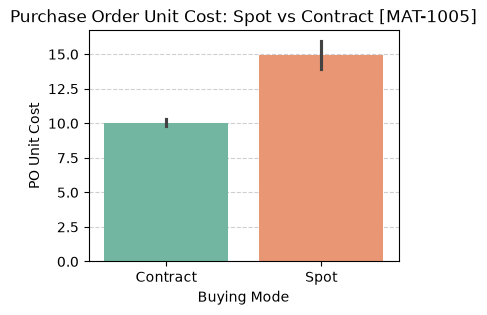

In [124]:
sns.barplot(
    data=(p_m_w[(p_m_w['POUnitCost'].notnull()) & (p_m_w['MaterialCode'] == 'MAT-1005')]
        [['POSampleID', 'MaterialCode', 'BuyingMode', 'DaysLeft', 'UnitPriceUSD', 'POUnitCost']]
        .sort_values(by=['MaterialCode', 'BuyingMode', 'POUnitCost'])), 
    x='BuyingMode', 
    y='POUnitCost', 
    palette='Set2'
)
plt.title('Purchase Order Unit Cost: Spot vs Contract [MAT-1005]')
plt.xlabel('Buying Mode')
plt.ylabel('PO Unit Cost')
plt.xticks()
plt.grid(True, axis='y', linestyle='--', alpha=0.6)
plt.gca().set_axisbelow(True)
plt.show()

2. Purchase Orders for **MAT-1003**:
    - In the **Spot** BuyingMode the **minimum** value for POUnitCost is **12.35**, while the **maximum** value for **Contract** BuyingMode is **7.00**. It is a difference of **5.35** in the POUnitCost.
    - This is also a material from Raw Materials category.
    - In this case the opportunistic buying is not cost-effective.

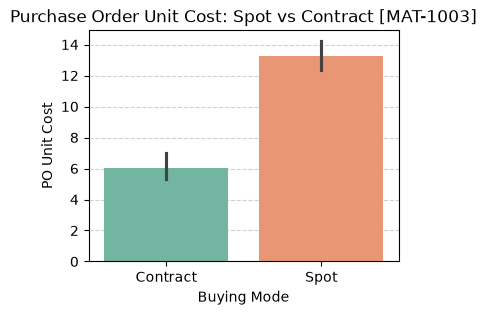

In [128]:
sns.barplot(
    data=(p_m_w[(p_m_w['POUnitCost'].notnull()) & (p_m_w['MaterialCode'] == 'MAT-1003')]
        [['POSampleID', 'MaterialCode', 'BuyingMode', 'DaysLeft', 'UnitPriceUSD', 'POUnitCost']]
        .sort_values(by=['MaterialCode', 'BuyingMode', 'POUnitCost'])), 
    x='BuyingMode', 
    y='POUnitCost', 
    palette='Set2'
)
plt.title('Purchase Order Unit Cost: Spot vs Contract [MAT-1003]')
plt.xlabel('Buying Mode')
plt.ylabel('PO Unit Cost')
plt.xticks()
plt.grid(True, axis='y', linestyle='--', alpha=0.6)
plt.gca().set_axisbelow(True)
plt.show()

3. **Conclusion:** When the value ShelfLifeDays is relatively small (less than 50 days), it is mainly for Raw Materials, the opportunistic buying at the end **would not be cost-effective**.

#### 6.2. Cases when Opportunistic Buying is **Cost-Effective**

1. Purchase Orders for **MAT-1010**:
    - In this case the maximum Spot BuyingMode POUnitPrice is smaller than the minimum Contract BuyingMode cost, it is a **difference** of at least **1.28** (at most 6.87).

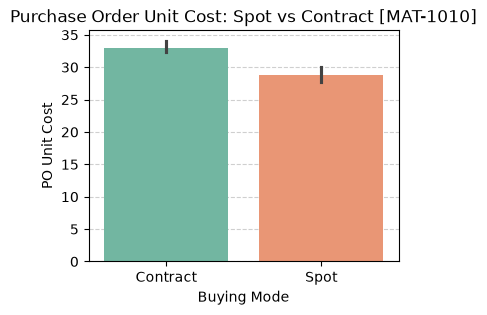

In [153]:
sns.barplot(
    data=(p_m_w[(p_m_w['POUnitCost'].notnull()) & (p_m_w['MaterialCode'] == 'MAT-1010')]
        [['POSampleID', 'MaterialCode', 'BuyingMode', 'DaysLeft', 'UnitPriceUSD', 'POUnitCost']]
        .sort_values(by=['MaterialCode', 'BuyingMode', 'POUnitCost'])), 
    x='BuyingMode', 
    y='POUnitCost', 
    palette='Set2'
)
plt.title('Purchase Order Unit Cost: Spot vs Contract [MAT-1010]')
plt.xlabel('Buying Mode')
plt.ylabel('PO Unit Cost')
plt.xticks()
plt.grid(True, axis='y', linestyle='--', alpha=0.6)
plt.gca().set_axisbelow(True)
plt.show()

2. Purchase Orders for **MAT-1014**:
    - In this case de **difference** between Spot and Contract is at least **3.84** (at most 6.15).

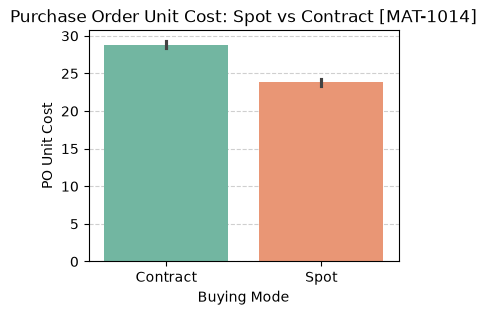

In [183]:
sns.barplot(
    data=(p_m_w[(p_m_w['POUnitCost'].notnull()) & (p_m_w['MaterialCode'] == 'MAT-1014')]
        [['POSampleID', 'MaterialCode', 'BuyingMode', 'DaysLeft', 'UnitPriceUSD', 'POUnitCost']]
        .sort_values(by=['MaterialCode', 'BuyingMode', 'POUnitCost'])), 
    x='BuyingMode', 
    y='POUnitCost', 
    palette='Set2'
)
plt.title('Purchase Order Unit Cost: Spot vs Contract [MAT-1014]')
plt.xlabel('Buying Mode')
plt.ylabel('PO Unit Cost')
plt.xticks()
plt.grid(True, axis='y', linestyle='--', alpha=0.6)
plt.gca().set_axisbelow(True)
plt.show()

3. **Conclusion:** For materials that are not in the Raw Materials category, it is mainly those which doesn't have short `ShelfLifeDays` (greater than 1000 days), the opportunistic buying **is cost-effective**.

### 7. Analysis of the Center Storage Capacity

There are three outliers in the Purchase Order dataset. The following table shows:
- PO10072-P, with OrderQuantity=19043, which is greater of the StorageCapacity of Center P: 18000
- PO10139-S, with OrderQuantity=43496, which is greater of the StorageCapacity of Center P: 42000
- PO10156-N, with OrderQuantity=60785, which is greater of the StorageCapacity of Center P: 60000



In [181]:
# OrderQuantity in Center N
p_m.loc[(p_m['OrderQuantity'] > (c_s.loc[c_s['Center']=='N', 'StorageCapacityUnits'].sum())) | 
    (p_m['OrderQuantity'] > (c_s.loc[c_s['Center']=='S', 'StorageCapacityUnits'].sum())) |
    (p_m['OrderQuantity'] > (c_s.loc[c_s['Center']=='P', 'StorageCapacityUnits'].sum())),
    ['POSampleID', 'MaterialCode', 'BuyingMode', 'Center', 'OrderQuantity']]

,POSampleID,MaterialCode,BuyingMode,Center,OrderQuantity
71,PO10072-P,MAT-1013,Spot,P,19043
138,PO10139-S,MAT-1005,Spot,S,43496
155,PO10156-N,MAT-1007,Spot,N,60785


As the Purchase Orders are in different dates, it is assumed this doesn't interfere in the previous analysis, because the capacity of Centers could be shared in order to take advantage of the Spot buying mode and the lower price.

### 8. Data Modeling and Structure

In the following image it is proposed the data model for this case study.

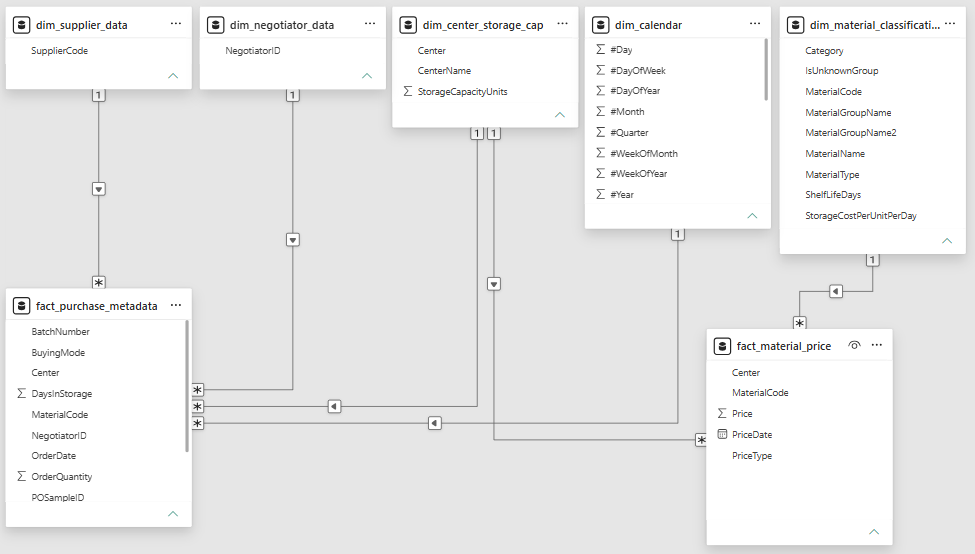

In [185]:
display(Image(filename='data-model.png'))

The model is a star schema type, and it is composed by:

1. **Fact Tables**
    - fact_purchase_metadata:
        - POSampleID
        - SupplierCode
        - MaterialCode
        - Center
        - OrderDate
        - BuyingMode
        - OrderQuantity
        - UnitPriceUSD
        - TransportCostUSD
        - DaysInStorage
        - BatchNumber
        - NegotiatorID

    - fact_material_price:
        - MaterialCode
        - Center
        - PriceType
        - Price
        - PriceDate

2. **Dimensions**
    - dim_material_classification:
        - MaterialCode, MaterialName, Category, MaterialGroupName, MaterialGroupName2, MaterialType, IsUnknownGroup, ShelfLifeDays, StorageCostPerUnitPerDay
    - dim_center_storage_cap:
        - Center, CenterName, StorageCapacityUnits
    - dim_supplier_data
        - SupplierCode
    - dim_negotiator_data
        - NegotiatiorID
    - dim_calendar
        - Date, #Year, #Month, #Day, ...